# Comparative Implementation of ML Regression Algorithms
**Dataset:** California Housing (20,640 districts), target = `median_house_value`

**Models:** Linear Regression, Decision Tree, Random Forest, Neural Network (MLP), XGBoost, KNN

**Setup:** 80:20 split (`random_state=42`), median imputation and scaling fitted on training data only.

**How to run:** Runtime > Run all. The dataset downloads automatically, so no upload is needed.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import io
import tarfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(42)
print('Libraries loaded')

Libraries loaded


## 1. Load the dataset automatically
The `housing.csv` file is downloaded from the Hands-On ML project on GitHub and read directly into pandas.

In [2]:
URL = 'https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.tgz'

try:
    with urllib.request.urlopen(URL, timeout=120) as response:
        archive_bytes = response.read()
except Exception as e:
    raise RuntimeError('Could not download the dataset from ' + URL + ' : ' + str(e))

with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode='r:gz') as tar:
    csv_member = [m for m in tar.getmembers() if m.name.endswith('housing.csv')][0]
    df = pd.read_csv(tar.extractfile(csv_member))

print('Dataset shape:', df.shape)
df.head()

Dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 2. Exploratory data analysis

In [3]:
df.info()
print()
print('Missing values per column:')
print(df.isnull().sum())
print()
print('ocean_proximity categories:')
print(df['ocean_proximity'].value_counts())
print()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Missing values per column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_va

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


## 3. Preprocessing and 80:20 split
- One-hot encode `ocean_proximity`
- Split 80:20 with `random_state=42`
- Fill missing `total_bedrooms` with the **training** median
- Create scaled copies for Linear Regression, KNN and Neural Network

In [4]:
target = 'median_house_value'

# Make category names safe for XGBoost (no '<' or spaces), then one-hot encode
df['ocean_proximity'] = df['ocean_proximity'].str.replace('<', 'LT ', regex=False).str.replace(' ', '_')
df = pd.get_dummies(df, columns=['ocean_proximity'], dtype=int)

X = df.drop(columns=[target])
y = df[target]

# 80:20 split, identical for all six models
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fill missing total_bedrooms with the TRAINING median only
imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)

# Scaled copies for Linear Regression, KNN and Neural Network (fitted on training data only)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Missing values left in training set:', int(X_train.isnull().sum().sum()))

Train: (16512, 13) | Test: (4128, 13)
Missing values left in training set: 0


## 4. Define the six models
Each entry is `(model, needs_scaled_features)`. The Neural Network also uses a scaled target, which is inverse-transformed automatically when predicting.

In [5]:
models = {
    'Linear Regression': (LinearRegression(), True),
    'Decision Tree': (DecisionTreeRegressor(max_depth=8, random_state=42), False),
    'Random Forest': (RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1), False),
    'Neural Network': (
        TransformedTargetRegressor(
            regressor=MLPRegressor(hidden_layer_sizes=(64, 32), activation='relu',
                                   solver='adam', max_iter=500, random_state=42),
            transformer=StandardScaler(),
        ),
        True,
    ),
    'XGBoost': (XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6,
                             random_state=42), False),
    'KNN': (KNeighborsRegressor(n_neighbors=5), True),
}

print('Models defined:', list(models.keys()))

Models defined: ['Linear Regression', 'Decision Tree', 'Random Forest', 'Neural Network', 'XGBoost', 'KNN']


## 5. Train, predict and evaluate
Metrics: MAE, MSE, RMSE and R².

In [6]:
results = []
predictions = {}

for name, (model, scaled) in models.items():
    X_tr = X_train_scaled if scaled else X_train
    X_te = X_test_scaled if scaled else X_test

    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    predictions[name] = y_pred

    mse = mean_squared_error(y_test, y_pred)
    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, y_pred),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R2': r2_score(y_test, y_pred),
    })
    print(name, 'finished')

results_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
results_df.index = results_df.index + 1
results_df.index.name = 'Rank'

results_df.style.format({'MAE': '{:,.0f}', 'MSE': '{:,.0f}', 'RMSE': '{:,.0f}', 'R2': '{:.4f}'})

Linear Regression finished
Decision Tree finished
Random Forest finished
Neural Network finished
XGBoost finished
KNN finished


,Model,MAE,MSE,RMSE,R2
Rank,,,,,
1,XGBoost,"30,508","2,127,612,566","46,126",0.8376
2,Random Forest,"31,548","2,392,580,046","48,914",0.8174
3,Neural Network,"35,851","2,799,353,935","52,909",0.7864
4,KNN,"40,870","3,769,707,700","61,398",0.7123
5,Decision Tree,"42,909","3,929,477,514","62,686",0.7001
6,Linear Regression,"50,670","4,908,290,571","70,059",0.6254


## 6. Actual vs predicted plots

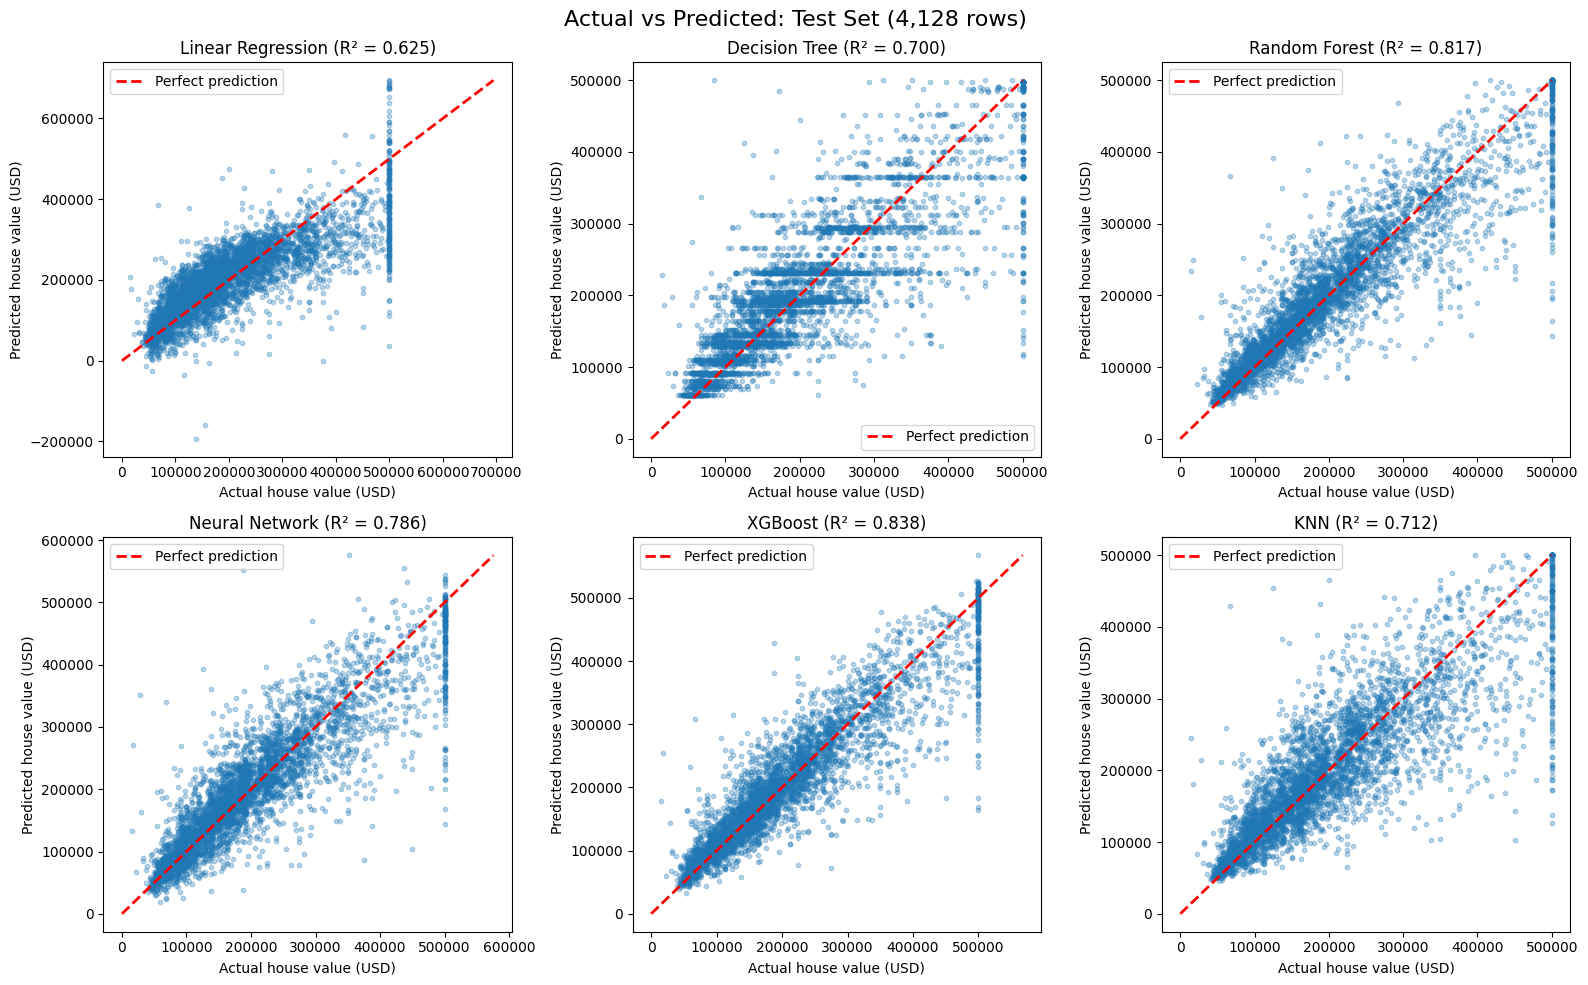

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.3, s=10)
    lims = [0, max(float(y_test.max()), float(np.max(y_pred)))]
    ax.plot(lims, lims, 'r--', lw=2, label='Perfect prediction')
    ax.set_title(name + ' (R² = ' + format(r2_score(y_test, y_pred), '.3f') + ')')
    ax.set_xlabel('Actual house value (USD)')
    ax.set_ylabel('Predicted house value (USD)')
    ax.legend()

plt.suptitle('Actual vs Predicted: Test Set (4,128 rows)', fontsize=16)
plt.tight_layout()
plt.savefig('actual_vs_predicted.png', dpi=150)
plt.show()

## 7. RMSE comparison chart

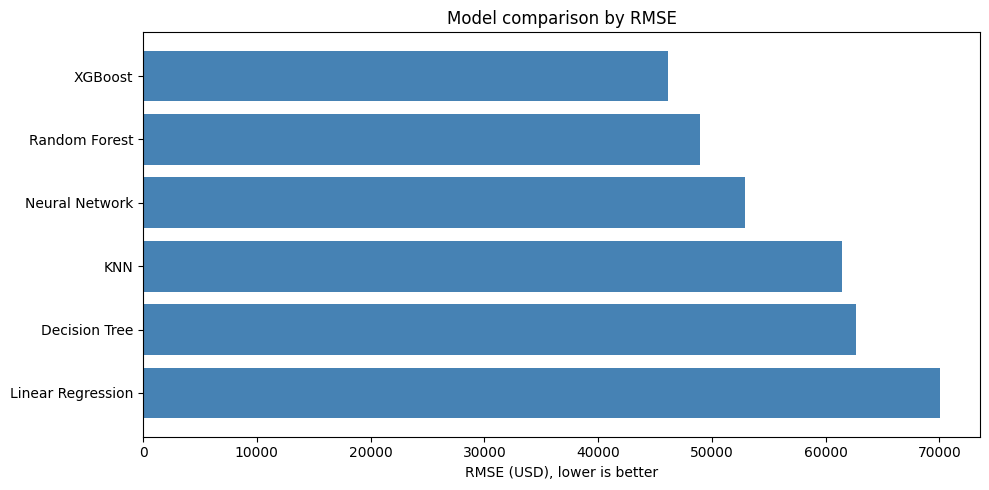

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(results_df['Model'], results_df['RMSE'], color='steelblue')
ax.invert_yaxis()
ax.set_xlabel('RMSE (USD), lower is better')
ax.set_title('Model comparison by RMSE')
plt.tight_layout()
plt.show()

## 8. Best model and export

In [9]:
best = results_df.iloc[0]
print('Best model:', best['Model'])
print('RMSE (USD):', format(best['RMSE'], ',.0f'))
print('R2:', format(best['R2'], '.4f'))

results_df.to_csv('comparison_table.csv')

try:
    from google.colab import files
    files.download('comparison_table.csv')
    files.download('actual_vs_predicted.png')
except ImportError:
    print('Files saved: comparison_table.csv, actual_vs_predicted.png')

Best model: XGBoost
RMSE (USD): 46,126
R2: 0.8376


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>